# Decision Tree task on Wifi DB

## 1. Load Dataset

In [9]:
import numpy as np
import matplotlib as plt
import math

def create_split_data(file_path, training_ratio):
    '''
    Load file data and split into training and testing data
    according to a specified ratio e.g 0.8 where 80% is training and 20% testing
    equally distributed set of each
    '''
    data = np.loadtxt(file_path)
    rooms = {}
    for i in data:
        r = i[7]
        if r in rooms:
            rooms[r].append(i)
        else:
            rooms[r] = [i]
    train = []
    test = []
    for k in rooms:
        room_data = rooms[k]
        split_point = int(len(room_data)*training_ratio)
        train += room_data[:split_point]
        test += room_data[split_point:]
    return np.array(train), np.array(test)

            
path = "wifi_db/clean_dataset.txt"
# path = "wifi_db/noisy_dataset.txt"
train, test = create_split_data(path, 0.8)
print(test)

[[-60. -54. -56. ... -78. -80.   1.]
 [-62. -53. -62. ... -79. -82.   1.]
 [-63. -51. -57. ... -79. -82.   1.]
 ...
 [-62. -59. -46. ... -87. -88.   4.]
 [-62. -58. -52. ... -90. -85.   4.]
 [-59. -50. -45. ... -88. -87.   4.]]


## 2. Create Decision Tree

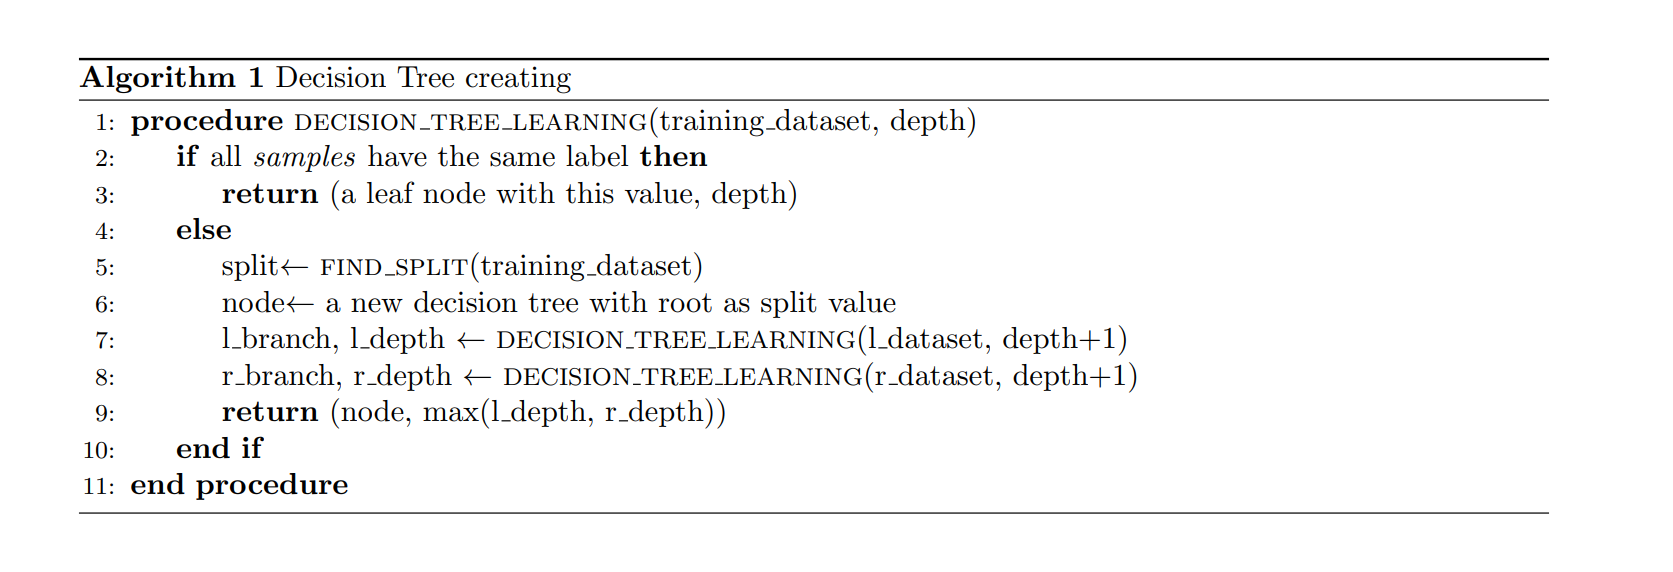

Psuedocode from *Artificial Intelligence: A Modern Approach* by Stuart Russell and Peter Norvig (Figure 18.5), but modified to
take into account that the considered dataset contains continuous attributes (see section 18.3.6 of the book).

In [94]:
def get_entropy(data):
    total = len(data)
    labels, counts = np.unique(data[:, -1], return_counts=True)
    entropy = 0
    for c in counts:
        entropy += -c/total * math.log2(c/total)
    return entropy

# Requires sorted data and the column the data was sorted on
def get_candidate_splits(sorted_data, col_sort):
    splits = []
    prev_val = None
    prev_label = None
    for d in sorted_data:
        # TODO: require a list of labels seperately so its more data agnostic
        if prev_val and prev_val != d[col_sort] and prev_label and prev_label != d[7]:
            mid = prev_val + ((d[col_sort] - prev_val) / 2)
            splits.append((mid, d[7]))
        prev_val = d[col_sort]
        prev_label = d[7]
    return splits

def find_split(data):
    '''
    - For each attribute order the values 
        - Find candidate split at decision boundaries
        - find split that gives us most IG
    - Repeat for each attribute and return the attr and split
    - resulting in the highest IG
    '''
    # Entropy for dataset
    h_data = get_entropy(data)
    # Last column is label
    no_attr = data.shape[1] - 1
    best_split = None
    for col in range(0, no_attr):
        sorted_data = data[data[:, col].argsort()]
        splits = get_candidate_splits(sorted_data, col)
        # Max information gain (split_point, Info Gain)
        max_ig = (-1, -1)
        for s in splits:
            filter_left = data[:, col] < s[0]
            filter_right = data[:, col] >= s[0]
    
            left_data = data[filter_left]
            right_data = data[filter_right]
            
            total_entropy = (len(left_data)/len(data)) * get_entropy(left_data) + (len(right_data)/len(data)) * get_entropy(right_data)
            max_ig = max(max_ig, (s[0], h_data - total_entropy), key= lambda x: x[1])
        if best_split and max_ig[1] > best_split[1][1]:
            best_split = (col, max_ig)
        if not best_split:
            best_split = (col, max_ig)
    return best_split


def decision_tree_learning(training_dataset, depth):
   
    
    labels, counts = np.unique(training_dataset[:, -1], return_counts=True)
    col, max_ig = find_split(training_dataset)
    if len(np.unique(labels)) == 1:
        node = {"attribute":"leaf", "value":labels[0], "left":"", "right":""}
        return (node, depth)
    # Edge case where we couldn't find an appropriate split candidate (due to noise)
    elif max_ig == (-1,-1):
        common = max(zip(labels,counts), key=lambda x: x[1])
        node = {"attribute":"leaf", "value":common[0], "left":"", "right":""}
        return (node, depth)
    else:
        val = max_ig[0]
        node = {"attribute":col, "value":val, "left":"", "right":""}
        filter_left = training_dataset[:, col] < val
        filter_right = training_dataset[:, col] >= val
        l_data = training_dataset[filter_left]
        r_data = training_dataset[filter_right]
        l_branch, l_depth = decision_tree_learning(l_data, depth+1)
        r_branch, r_depth = decision_tree_learning(r_data, depth+1)
        node["left"] = l_branch
        node["right"] = r_branch
        return (node, max(l_depth, r_depth))

tree = decision_tree_learning(train, 0)
print(tree)

({'attribute': 0, 'value': np.float64(-54.5), 'left': {'attribute': 4, 'value': np.float64(-59.5), 'left': {'attribute': 3, 'value': np.float64(-55.5), 'left': {'attribute': 4, 'value': np.float64(-64.5), 'left': {'attribute': 'leaf', 'value': np.float64(1.0), 'left': '', 'right': ''}, 'right': {'attribute': 6, 'value': np.float64(-85.5), 'left': {'attribute': 3, 'value': np.float64(-60.5), 'left': {'attribute': 4, 'value': np.float64(-62.0), 'left': {'attribute': 'leaf', 'value': np.float64(1.0), 'left': '', 'right': ''}, 'right': {'attribute': 'leaf', 'value': np.float64(4.0), 'left': '', 'right': ''}}, 'right': {'attribute': 1, 'value': np.float64(-53.0), 'left': {'attribute': 'leaf', 'value': np.float64(4.0), 'left': '', 'right': ''}, 'right': {'attribute': 'leaf', 'value': np.float64(3.0), 'left': '', 'right': ''}}}, 'right': {'attribute': 'leaf', 'value': np.float64(1.0), 'left': '', 'right': ''}}}, 'right': {'attribute': 0, 'value': np.float64(-57.5), 'left': {'attribute': 0, 'v

In [107]:
'''
            Pred 1, Pred 2, Pred 3, Pred 4   
Row actual 1  TP    
Row actual 2        TP
Row actual 3                 TP
Row actual 4                        TP

'''
# Todo: implement confusion matrix
def get_confusion_matrix(test_predictions, test_real):
    conf_mat = np.zeros((4,4), float)
    return conf_mat
    
    
def get_accuracy(test_predictions, test_real):
    assert(test_predictions.shape == test_real.shape)
    correct = 0
    for i in range(len(test_predictions)):
        if test_predictions[i] == test_real[i]:
            correct += 1
    return correct/len(test_predictions)

    
def evaluate(test_data, tree):
    point = test_data[0]
    test_real = test_data[:, -1]
    test_predictions = []
    for point in test_data:
        node = tree[0]
        while node["attribute"] != "leaf":
            if point[node["attribute"]] < node["value"]:
                node = node["left"]
            else:
                node = node["right"]
        test_predictions.append(node["value"])
    test_predictions = np.array(test_predictions)
    conf_mat = get_confusion_matrix(test_predictions, test_real)
    return get_accuracy(test_predictions, test_real)
    

In [108]:
# Full pipeline


path = "wifi_db/clean_dataset.txt"
train, test = create_split_data(path, 0.8)
tree = decision_tree_learning(train, 0)
accuracy_clean = evaluate(test, tree)

path = "wifi_db/noisy_dataset.txt"
train, test = create_split_data(path, 0.8)
tree = decision_tree_learning(train, 0)
accuracy_noisy = evaluate(test, tree)

print(f"Clean dataset accuracy: {accuracy_clean*100}%")
print(f"Noisy dataset accuracy: {accuracy_noisy*100}%")

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
Clean dataset accuracy: 96.0%
Noisy dataset accuracy: 78.05486284289277%
